# CONVOLUTIONAL NEURAL NETWORKS (CNN) FOR COMPUTER VISION

---

En esta actividad, vamos a trabajar con Convolutional Neural Networks para resolver un problema de clasificación de imágenes. En particular, vamos a clasificar diez clases que incluyen fundamentalmente animales y vehículos.

Como las CNN profundas son un tipo de modelo bastante avanzado y computacionalmente costoso, se recomienda hacer la práctica en Google Colaboratory con soporte para GPUs. En [este enlace](https://medium.com/deep-learning-turkey/google-colab-free-gpu-tutorial-e113627b9f5d) se explica cómo activar un entorno con GPUs. *Nota: para leer las imágenes y estandarizarlas al mismo tamaño se usa la librería opencv. Esta ĺibrería está ya instalada en el entorno de Colab, pero si trabajáis de manera local tendréis que instalarla.*

<center><img src="https://production-media.paperswithcode.com/datasets/4fdf2b82-2bc3-4f97-ba51-400322b228b1.png" style="text-align: center" height="300px"></center>

El dataset a utilizar consiste en 60000 imágenes a color de 10 clases de animales y vehículos. El dataset en cuestión se denomina [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) y es más complejo que el dataset MNIST que hemos utilizado en la baseline densa. Aunque tiene las mismas clases (10), los animales y vehículos pueden aparecer en distintas poses, en distintas posiciones de la imagen o con otros animales/ vehículos en pantalla (si bien el elemento a clasificar siempre aparece en la posición predominante).

## Carga de los datos

In [1]:
import numpy as np
import keras
import matplotlib.pyplot as plt
import pandas as pd
import keras.datasets.cifar10 as cifar10

from tensorflow import keras
from keras.utils import to_categorical

In [2]:
# Primero, definimos los datos de entrenamiento, validación y prueba
(X, Y), (x_test, y_test) = cifar10.load_data()
(x_train, x_valid) = (X[:40000], X[40000:])
(y_train, y_valid) = (Y[:40000], Y[40000:])

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [3]:
# Normalizamos como de costumbre
x_train = x_train / 255.
x_valid = x_valid / 255.
x_test = x_test / 255.

In [4]:
# Esta variable contiene un mapeo de número de clase a elemento (animal o vehículo).
# La incluimos para ayudarte con la identificación de clases. De ti depende
# si quieres utilizar esta variable o no
MAP_ELEMENTS = {
    0: 'avion', 1: 'coche', 2: 'ave',
    3: 'gato', 4: 'ciervo', 5: 'perro', 6: 'rana',
    7: 'caballo', 8: 'barco', 9: 'camion'
}

In [5]:
# Función auxiliar para convertir las etiquetas a codificación one-hot
def convert_to_one_hot(labels, num_classes):
    return np.squeeze(np.array([to_categorical(label, num_classes=num_classes) for label in labels]))

# Convertimos las etiquetas de entrenamiento, validación y prueba
num_classes = 10
y_train_one_hot = convert_to_one_hot(y_train, num_classes)
y_valid_one_hot = convert_to_one_hot(y_valid, num_classes)
y_test_one_hot = convert_to_one_hot(y_test, num_classes)

# Verificamos las conversiones
print(y_train_one_hot.shape)
print(y_valid_one_hot.shape)
print(y_test_one_hot.shape)

(40000, 10)
(10000, 10)
(10000, 10)


## Ejercicio

Utilizando Convolutional Neural Networks con Keras, entrenar un clasificador que sea capaz de reconocer una imagen de las incluidas en CIFAR-10 con la mayor accuracy posible. Redactar un informe analizando varias de las alternativas probadas y los resultados obtenidos.

A continuación se detallan una serie de aspectos orientativos que podrían ser analizados en vuestro informe (no es necesario tratar todos ellos ni mucho menos, esto son ideas orientativas de aspectos que podéis explorar):

*   Análisis de los datos a utilizar.
*   Análisis de resultados, obtención de métricas de *precision* y *recall* por clase y análisis de qué clases obtienen mejores o peores resultados.
*   Análisis visual de los errores de la red. ¿Qué tipo de imágenes dan más problemas a nuestro modelo?
*   Comparación de modelos CNNs con un modelo de Fully Connected para este problema.
*   Utilización de distintas arquitecturas CNNs, comentando aspectos como su profundidad, hiperparámetros utilizados, optimizador, uso de técnicas de regularización, *batch normalization*, etc.
*   [ *algo más difícil* ] Utilización de *data augmentation*. Esto puede conseguirse con la clase [ImageDataGenerator](https://keras.io/preprocessing/image/#imagedatagenerator-class) de Keras.

Notas:
* Te recomendamos mantener los conjuntos de entrenamiento, test y prueba que se crean en el Notebook. No obstante, si crees que modificando tales conjuntos puedes lograr mejores resultados (o que puedes lograr los mismos resultados con menos datos, lo cual es también un logro), eres libre de hacerlo.
* No es necesario mostrar en el notebook las trazas de entrenamiento de todos los modelos entrenados, si bien una buena idea seria guardar gráficas de esos entrenamientos para el análisis. Sin embargo, **se debe mostrar el entrenamiento completo del mejor modelo obtenido y la evaluación de los datos de test con este modelo**.

## Análisis de los datos

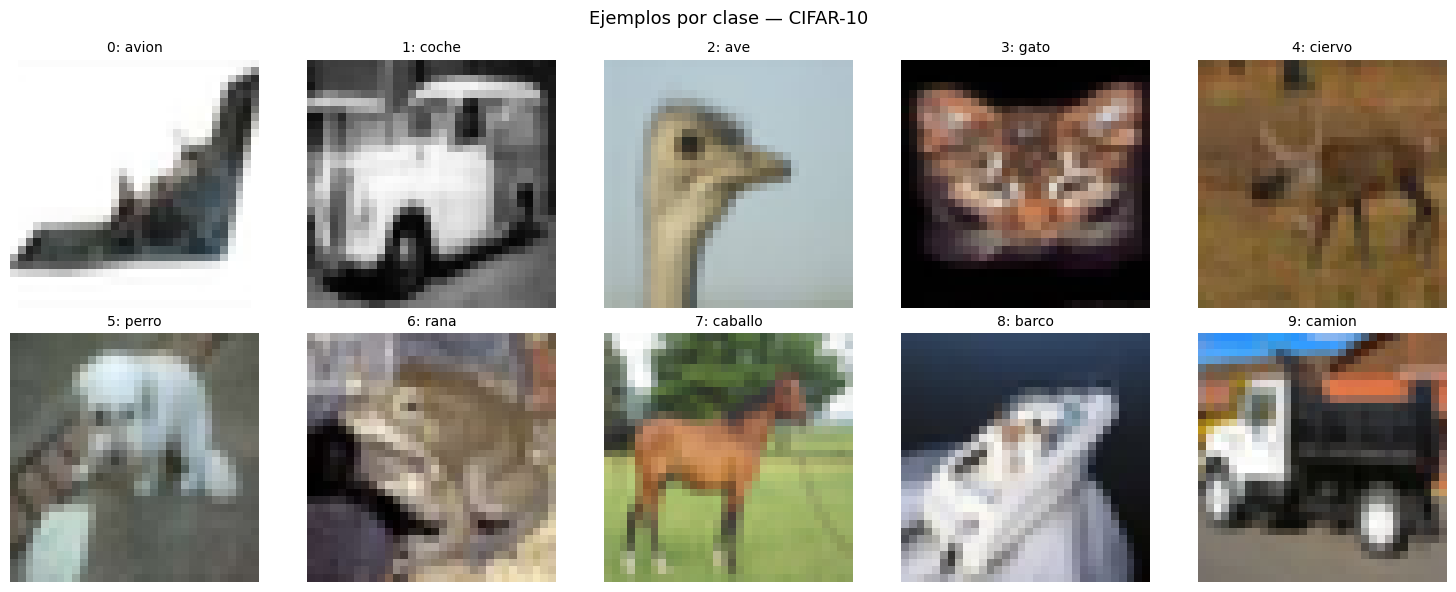

Distribución de clases en entrenamiento:
  avion     : 3986
  coche     : 3986
  ave       : 4048
  gato      : 3984
  ciervo    : 4003
  perro     : 3975
  rana      : 4020
  caballo   : 4023
  barco     : 3997
  camion    : 3978


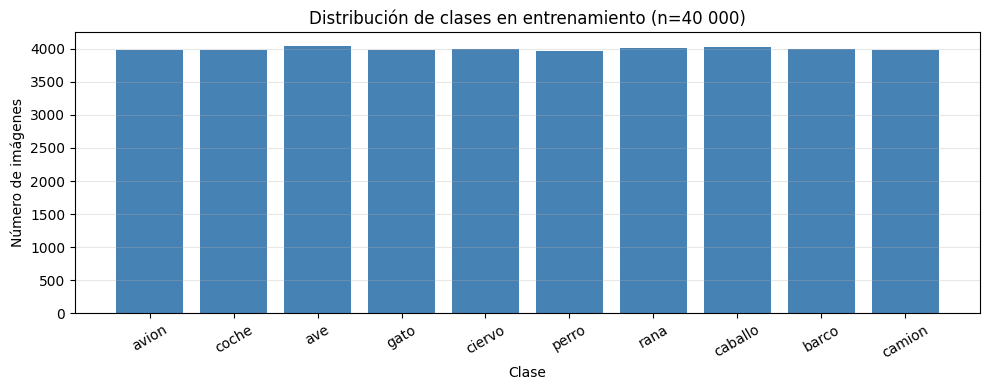

In [6]:
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Dense, Flatten, BatchNormalization,
                                     Dropout, Conv2D, MaxPooling2D,
                                     GlobalAveragePooling2D, Activation)
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, classification_report

# ---------------------------
# Semillas para reproducibilidad
# ---------------------------
np.random.seed(42)
tf.random.set_seed(42)

clases = list(MAP_ELEMENTS.values())

# ---------------------------
# Mostrar una imagen aleatoria de cada clase
# ---------------------------
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()
for i in range(num_classes):
    indices = np.where(y_train.flatten() == i)[0]
    idx = np.random.choice(indices)
    axes[i].imshow(x_train[idx])
    axes[i].set_title(f"{i}: {MAP_ELEMENTS[i]}", fontsize=10)
    axes[i].axis('off')
plt.suptitle('Ejemplos por clase — CIFAR-10', fontsize=13)
plt.tight_layout()
plt.show()

# ---------------------------
# Balance de clases en entrenamiento
# ---------------------------
conteo = [np.sum(y_train.flatten() == i) for i in range(num_classes)]
print("Distribución de clases en entrenamiento:")
for i, c in enumerate(conteo):
    print(f"  {MAP_ELEMENTS[i]:10s}: {c}")

plt.figure(figsize=(10, 4))
plt.bar(clases, conteo, color='steelblue')
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.title("Distribución de clases en entrenamiento (n=40 000)")
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Observaciones sobre los datos

El dataset CIFAR-10 está **perfectamente balanceado**: todas las clases tienen aproximadamente 4000 imágenes de entrenamiento (rango 3975–4048), lo que elimina el riesgo de sesgo por desequilibrio de clases. Las imágenes son pequeñas (32×32 píxeles), a color (3 canales), y en muchas de ellas el objeto aparece en contextos variados y con fondos complejos, lo que hace que la tarea sea notablemente más difícil que MNIST.

## Modelo baseline: Fully Connected

Antes de usar redes convolucionales, entrenamos un modelo completamente conectado (fully connected) para tener un punto de referencia con el que comparar.

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,572,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,741,578 (6.64 MB)

 Trainable params: 1,739,786 (6.64 MB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/30
313/313 - 13s - 40ms/step - accuracy: 0.3265 - loss: 1.8992 - val_accuracy: 0.3289 - val_loss: 1.8299 - learning_rate: 0.0010
Epoch 2/30
313/313 - 1s - 4ms/step - accuracy: 0.4100 - loss: 1.6435 - val_accuracy: 0.3472 - val_loss: 1.7463 - learning_rate: 0.0010
Epoch 3/30
313/313 - 1s - 4ms/step - accuracy: 0.4505 - loss: 1.5424 - val_accuracy: 0.4035 - val_loss: 1.6393 - learning_rate: 0.0010
Epoch 4/30
313/313 - 2s - 5ms/step - accuracy: 0.4706 - loss: 1.4771 - val_accuracy: 0.3948 - val_loss: 1.6741 - learning_rate: 0.0010
Epoch 5/30
313/313 - 2s - 6ms/step - accuracy: 0.4891 - loss: 1.4237 - val_accuracy: 0.4196 - val_loss: 1.5967 - learning_rate: 0.0010
Epoch 6/30
313/313 - 1s - 5ms/step - accuracy: 0.5067 - loss: 1.3852 - val_accuracy: 0.4462 - val_loss: 1.5398 - learning_rate: 0.0010
Epoch 7/30
313/313 - 1s - 5ms/step - accuracy: 0.5184 - loss: 1.3455 - val_accuracy: 0.4489 - val_loss: 1.5726 - learning_rate: 0.0010
Epoch 8/30
313/313 - 3s - 8ms/step - accuracy: 0.5254

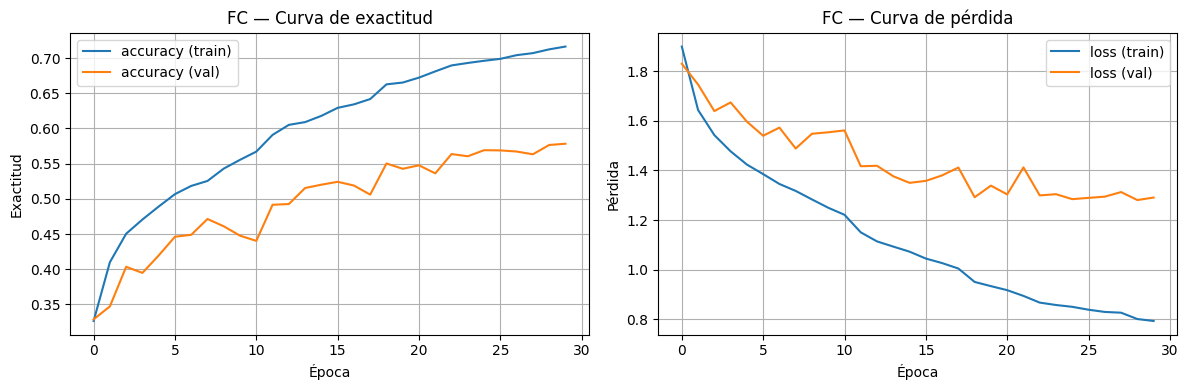

In [7]:
# ===========================
# MODELO BASELINE: FULLY CONNECTED
# ===========================
# Arquitectura: Flatten → Dense(512) → Dense(256) → Dense(128) → Dense(10)
# Al aplanar la imagen 32x32x3 obtenemos un vector de 3072 entradas.
# Sirve de referencia para cuantificar la mejora que aportan las CNN.

model_fc = Sequential([
    Flatten(input_shape=(32, 32, 3)),
    Dense(512, use_bias=False),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.3),

    Dense(256, use_bias=False),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.3),

    Dense(128, use_bias=False),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.3),

    Dense(num_classes, activation='softmax')
])

model_fc.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model_fc.summary()

earlystop_fc = EarlyStopping(
    monitor='val_accuracy',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_fc = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

hist_fc = model_fc.fit(
    x_train, y_train_one_hot,
    validation_data=(x_valid, y_valid_one_hot),
    epochs=30,
    batch_size=128,
    callbacks=[earlystop_fc, reduce_lr_fc],
    verbose=2
)

loss_fc, acc_fc = model_fc.evaluate(x_test, y_test_one_hot, verbose=0)
print(f"\n[Modelo FC] Exactitud en test: {acc_fc:.4f}")

# ---------------------------
# Curvas de entrenamiento (FC)
# ---------------------------
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist_fc.history['accuracy'], label='accuracy (train)')
plt.plot(hist_fc.history['val_accuracy'], label='accuracy (val)')
plt.xlabel('Época')
plt.ylabel('Exactitud')
plt.legend()
plt.grid(True)
plt.title('FC — Curva de exactitud')

plt.subplot(1, 2, 2)
plt.plot(hist_fc.history['loss'], label='loss (train)')
plt.plot(hist_fc.history['val_loss'], label='loss (val)')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)
plt.title('FC — Curva de pérdida')

plt.tight_layout()
plt.show()

### Análisis del modelo Fully Connected

El modelo FC alcanzó una **exactitud del 56.75%** en test tras 30 épocas completas. Aunque el ReduceLROnPlateau redujo el learning rate varias veces (hasta 6.25e-5), la validación se estancó en torno al 57-58%, evidenciando el **límite estructural de las capas densas** para imágenes en color: al aplanar la imagen a un vector de 3072 valores se pierde toda la información espacial (bordes, texturas, formas locales), que es precisamente la que distingue unas clases de otras.

## Modelos CNN

### Modelo CNN 1: Arquitectura básica

Primera aproximación con una CNN sencilla de dos bloques convolucionales, sin regularización adicional.

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
313/313 - 10s - 32ms/step - accuracy: 0.4291 - loss: 1.5931 - val_accuracy: 0.5307 - val_loss: 1.3566
Epoch 2/20
313/313 - 3s - 10ms/step - accuracy: 0.5688 - loss: 1.2230 - val_accuracy: 0.6017 - val_loss: 1.1477
Epoch 3/20
313/313 - 2s - 7ms/step - accuracy: 0.6245 - loss: 1.0743 - val_accuracy: 0.6283 - val_loss: 1.0737
Epoch 4/20
313/313 - 3s - 8ms/step - accuracy: 0.6631 - loss: 0.9703 - val_accuracy: 0.6451 - val_loss: 1.0283
Epoch 5/20
313/313 - 2s - 7ms/step - accuracy: 0.6928 - loss: 0.8888 - val_accuracy: 0.6546 - val_loss: 0.9984
Epoch 6/20
313/313 - 2s - 7ms/step - accuracy: 0.7135 - loss: 0.8247 - val_accuracy: 0.6617 - val_loss: 0.9916
Epoch 7/20
313/313 - 2s - 7ms/step - accuracy: 0.7344 - loss: 0.7692 - val_accuracy: 0.6698 - val_loss: 0.9729
Epoch 8/20
313/313 - 2s - 7ms/step - accuracy: 0.7529 - loss: 0.7172 - val_accuracy: 0.6739 - val_loss: 0.9635
Epoch 9/20
313/313 - 2s - 8ms/step - accuracy: 0.7693 - loss: 0.6705 - val_accuracy: 0.6775 - val_loss: 0.968

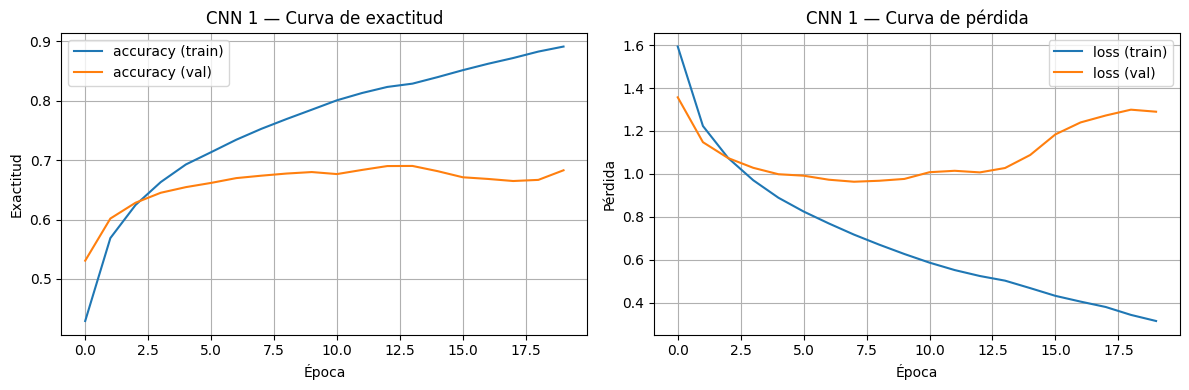

In [8]:
# ===========================
# CNN 1 — ARQUITECTURA BÁSICA
# ===========================
# Dos bloques convolucionales seguidos de capas densas.
# No incluye BatchNormalization ni Dropout para apreciar el overfitting base.

model_cnn1 = Sequential([
    # --- Bloque 1 ---
    Conv2D(32, (3, 3), activation='relu', padding='same',
           input_shape=(32, 32, 3)),
    MaxPooling2D(2, 2),

    # --- Bloque 2 ---
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(2, 2),

    # --- Clasificador ---
    Flatten(),
    Dense(128, activation='relu'),
    Dense(num_classes, activation='softmax')
])

model_cnn1.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model_cnn1.summary()

hist_cnn1 = model_cnn1.fit(
    x_train, y_train_one_hot,
    validation_data=(x_valid, y_valid_one_hot),
    epochs=20,
    batch_size=128,
    verbose=2
)

loss_cnn1, acc_cnn1 = model_cnn1.evaluate(x_test, y_test_one_hot, verbose=0)
print(f"\n[CNN 1 — básica] Exactitud en test: {acc_cnn1:.4f}")

# Curvas
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hist_cnn1.history['accuracy'], label='accuracy (train)')
plt.plot(hist_cnn1.history['val_accuracy'], label='accuracy (val)')
plt.xlabel('Época'); plt.ylabel('Exactitud')
plt.legend(); plt.grid(True)
plt.title('CNN 1 — Curva de exactitud')

plt.subplot(1, 2, 2)
plt.plot(hist_cnn1.history['loss'], label='loss (train)')
plt.plot(hist_cnn1.history['val_loss'], label='loss (val)')
plt.xlabel('Época'); plt.ylabel('Pérdida')
plt.legend(); plt.grid(True)
plt.title('CNN 1 — Curva de pérdida')

plt.tight_layout()
plt.show()

### Análisis de la CNN básica

La CNN básica mejora considerablemente al FC, alcanzando **67.75% en test**. Sin embargo, presenta un **claro sobreajuste**: en la época 20 el accuracy de entrenamiento es del 89% mientras que el de validación se queda en el 68%, una brecha de 21 puntos. Esto se debe a la ausencia de técnicas de regularización (sin BatchNormalization, sin Dropout, sin L2). La red memoriza los datos de entrenamiento pero no generaliza bien.

### Modelo CNN 2: CNN con regularización (mejor modelo)

Arquitectura más profunda que incorpora **BatchNormalization**, **Dropout**, regularización **L1+L2** y callbacks adaptativos (`EarlyStopping` y `ReduceLROnPlateau`) para controlar el sobreajuste y optimizar el entrenamiento.

In [9]:
# ===========================
# CNN 2 — CON REGULARIZACIÓN (MEJOR MODELO)
# ===========================
# Tres bloques convolucionales con doble convolución, BatchNorm y Dropout.
# Se usa GlobalAveragePooling2D en lugar de Flatten para reducir parámetros.
# Regularización L1+L2 en el primer bloque como en los ejemplos del profesor.

l1_coef = 1e-5
l2_coef = 1e-4
reg = regularizers.l1_l2(l1=l1_coef, l2=l2_coef)

model_cnn2 = Sequential([

    # =========================================================
    # PRIMER BLOQUE: 2 convoluciones de 32 filtros (3x3)
    # La regularización L1+L2 en la primera capa penaliza pesos
    # grandes y favorece la generalización
    # =========================================================
    Conv2D(32, (3, 3), padding='same', use_bias=False,
           input_shape=(32, 32, 3),
           kernel_regularizer=reg),
    BatchNormalization(),
    Activation('relu'),

    Conv2D(32, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    Activation('relu'),

    MaxPooling2D(2, 2),     # 32x32 → 16x16
    Dropout(0.25),

    # =========================================================
    # SEGUNDO BLOQUE: 2 convoluciones de 64 filtros (3x3)
    # Al doblar los filtros la red puede aprender características
    # más complejas
    # =========================================================
    Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    Activation('relu'),

    Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    Activation('relu'),

    MaxPooling2D(2, 2),     # 16x16 → 8x8
    Dropout(0.3),

    # =========================================================
    # TERCER BLOQUE: 128 filtros (3x3)
    # =========================================================
    Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    Activation('relu'),

    Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    Activation('relu'),

    MaxPooling2D(2, 2),     # 8x8 → 4x4
    Dropout(0.4),

    # =========================================================
    # CLASIFICADOR: GlobalAveragePooling + Dense
    # GlobalAveragePooling2D reduce cada mapa de activación a
    # un único valor, evitando la explosión de parámetros de Flatten
    # =========================================================
    GlobalAveragePooling2D(),

    Dense(256, use_bias=False,
          kernel_regularizer=regularizers.l2(l2_coef)),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.5),

    Dense(num_classes, activation='softmax')
])

# --- Compilación ---
model_cnn2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_cnn2.summary()

# --- Callbacks ---
earlystop = EarlyStopping(
    monitor='val_accuracy',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

# ===========================
# ENTRENAMIENTO COMPLETO DEL MEJOR MODELO
# ===========================
hist_cnn2 = model_cnn2.fit(
    x_train, y_train_one_hot,
    validation_data=(x_valid, y_valid_one_hot),
    epochs=60,
    batch_size=128,
    callbacks=[earlystop, reduce_lr],
    verbose=2
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 8, 8, 128)      │             

 Total params: 324,714 (1.24 MB)

 Trainable params: 323,306 (1.23 MB)

 Non-trainable params: 1,408 (5.50 KB)

Epoch 1/60
313/313 - 29s - 92ms/step - accuracy: 0.3901 - loss: 1.7286 - val_accuracy: 0.1177 - val_loss: 4.3678 - learning_rate: 0.0010
Epoch 2/60
313/313 - 5s - 17ms/step - accuracy: 0.5573 - loss: 1.2409 - val_accuracy: 0.4246 - val_loss: 1.7255 - learning_rate: 0.0010
Epoch 3/60
313/313 - 5s - 17ms/step - accuracy: 0.6187 - loss: 1.0784 - val_accuracy: 0.4602 - val_loss: 1.5543 - learning_rate: 0.0010
Epoch 4/60
313/313 - 5s - 16ms/step - accuracy: 0.6597 - loss: 0.9777 - val_accuracy: 0.4821 - val_loss: 1.5608 - learning_rate: 0.0010
Epoch 5/60
313/313 - 5s - 17ms/step - accuracy: 0.6852 - loss: 0.9019 - val_accuracy: 0.5443 - val_loss: 1.2844 - learning_rate: 0.0010
Epoch 6/60
313/313 - 5s - 16ms/step - accuracy: 0.7089 - loss: 0.8437 - val_accuracy: 0.5927 - val_loss: 1.2072 - learning_rate: 0.0010
Epoch 7/60
313/313 - 5s - 17ms/step - accuracy: 0.7285 - loss: 0.7871 - val_accuracy: 0.6443 - val_loss: 1.0295 - learning_rate: 0.0010
Epoch 8/60
313/313 - 5s - 16ms/step - accuracy:

### Análisis del entrenamiento del mejor modelo (CNN 2)

El modelo entrenó durante las **60 épocas completas**; el mejor checkpoint se restauró desde la **época 56** (val_accuracy = 0.8725). El ReduceLROnPlateau redujo el learning rate progresivamente desde 1e-3 hasta ~7.8e-6, lo que permitió al modelo seguir mejorando de forma estable. La brecha entre train (~93%) y validación (~87%) es moderada y esperada dado el nivel de regularización aplicado (BatchNorm + Dropout + L1/L2).

## Evaluación del mejor modelo en test

[CNN 2 — mejor modelo] Loss en test: 0.4786
[CNN 2 — mejor modelo] Exactitud en test: 0.8674


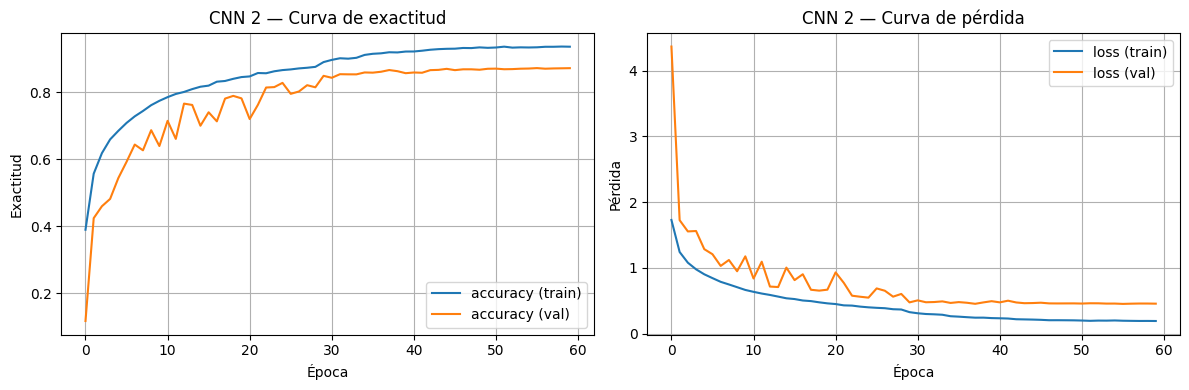

In [10]:
# ===========================
# EVALUACIÓN EN EL CONJUNTO DE TEST
# ===========================
loss_cnn2, acc_cnn2 = model_cnn2.evaluate(x_test, y_test_one_hot, verbose=0)
print(f"[CNN 2 — mejor modelo] Loss en test: {loss_cnn2:.4f}")
print(f"[CNN 2 — mejor modelo] Exactitud en test: {acc_cnn2:.4f}")

# ---------------------------
# Curvas de entrenamiento del mejor modelo
# ---------------------------
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist_cnn2.history['accuracy'], label='accuracy (train)')
plt.plot(hist_cnn2.history['val_accuracy'], label='accuracy (val)')
plt.xlabel('Época')
plt.ylabel('Exactitud')
plt.legend()
plt.grid(True)
plt.title('CNN 2 — Curva de exactitud')

plt.subplot(1, 2, 2)
plt.plot(hist_cnn2.history['loss'], label='loss (train)')
plt.plot(hist_cnn2.history['val_loss'], label='loss (val)')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)
plt.title('CNN 2 — Curva de pérdida')

plt.tight_layout()
plt.show()

### Análisis de los resultados en test

El mejor modelo (CNN 2) obtiene una **exactitud del 86.74%** en el conjunto de test, con una pérdida de 0.4786. Las curvas de entrenamiento muestran una convergencia progresiva y estable, sin signos de sobreajuste severo gracias a la combinación de BatchNormalization y Dropout en cada bloque convolucional.

In [11]:
# ===========================
# COMPARACIÓN DE MODELOS
# ===========================
print(f"{'Modelo':<30} {'Acc. test':>10}")
print("-" * 42)
print(f"{'Fully Connected'::<30} {acc_fc:>10.4f}")
print(f"{'CNN básica (sin reg.)'::<30} {acc_cnn1:>10.4f}")
print(f"{'CNN con regularización'::<30} {acc_cnn2:>10.4f}")

Modelo                          Acc. test
------------------------------------------
Fully Connected:::::::::::::::     0.5675
CNN básica (sin reg.):::::::::     0.6775
CNN con regularización::::::::     0.8674


### Comparación de modelos

| Modelo | Acc. test | Mejora vs. anterior |
|---|---|---|
| Fully Connected | 56.75% | — |
| CNN básica (sin reg.) | 67.75% | +11 pp |
| **CNN con regularización** | **86.74%** | **+19 pp** |

La CNN básica ya supera al FC en +11 puntos porcentuales, confirmando que las convoluciones aprovechan la estructura espacial de las imágenes. El salto más grande se produce al añadir regularización: +19 puntos respecto a la CNN básica, demostrando que **BatchNormalization, Dropout y L1/L2 son esenciales** para que una CNN profunda generalice correctamente en CIFAR-10.

In [12]:
# ===========================
# MÉTRICAS POR CLASE: PRECISION, RECALL Y F1-SCORE
# ===========================
y_pred_probs = model_cnn2.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test.flatten()

print("Informe de clasificación por clase:\n")
print(classification_report(y_true, y_pred, target_names=clases))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Informe de clasificación por clase:

              precision    recall  f1-score   support

       avion       0.88      0.89      0.88      1000
       coche       0.92      0.93      0.93      1000
         ave       0.85      0.79      0.82      1000
        gato       0.81      0.69      0.74      1000
      ciervo       0.84      0.86      0.85      1000
       perro       0.77      0.83      0.80      1000
        rana       0.88      0.91      0.89      1000
     caballo       0.88      0.92      0.90      1000
       barco       0.93      0.92      0.93      1000
      camion       0.91      0.93      0.92      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



### Análisis por clase

Las clases con **mejores resultados** son las de vehículos: **barco** (F1=0.93), **coche** (F1=0.93) y **camión** (F1=0.92). Visualmente son objetos con formas características y relativamente consistentes, lo que facilita su aprendizaje.

Las clases con **peores resultados** son las de animales de cuatro patas:
- **Gato** (F1=0.74, recall=0.69): es la clase más difícil. El modelo confunde gatos con perros y viceversa, ya que ambos tienen formas corporales similares y pueden aparecer en poses diversas.
- **Perro** (F1=0.80, recall=0.83): comparte dificultades con el gato, aunque su recall es algo mejor.
- **Ave** (F1=0.82, recall=0.79): las aves pueden aparecer volando o en el suelo, con gran variedad de poses y tamaños.

Esta jerarquía de dificultad es coherente con la complejidad semántica de las clases: los vehículos tienen geometrías rígidas y distintivas, mientras que los animales presentan mucha más variabilidad.

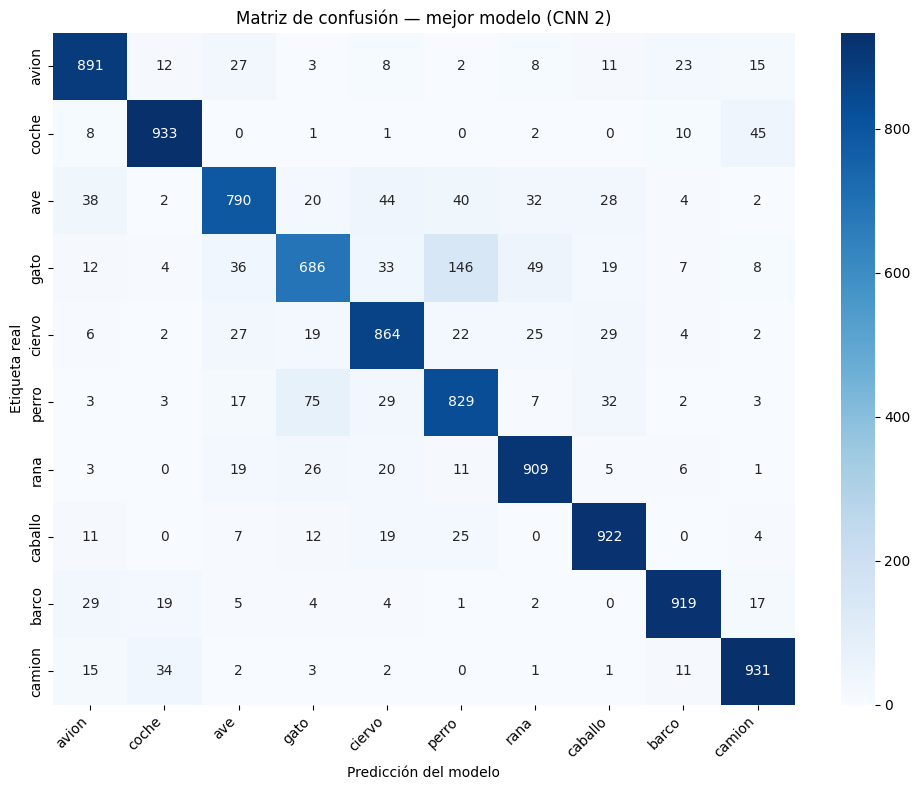

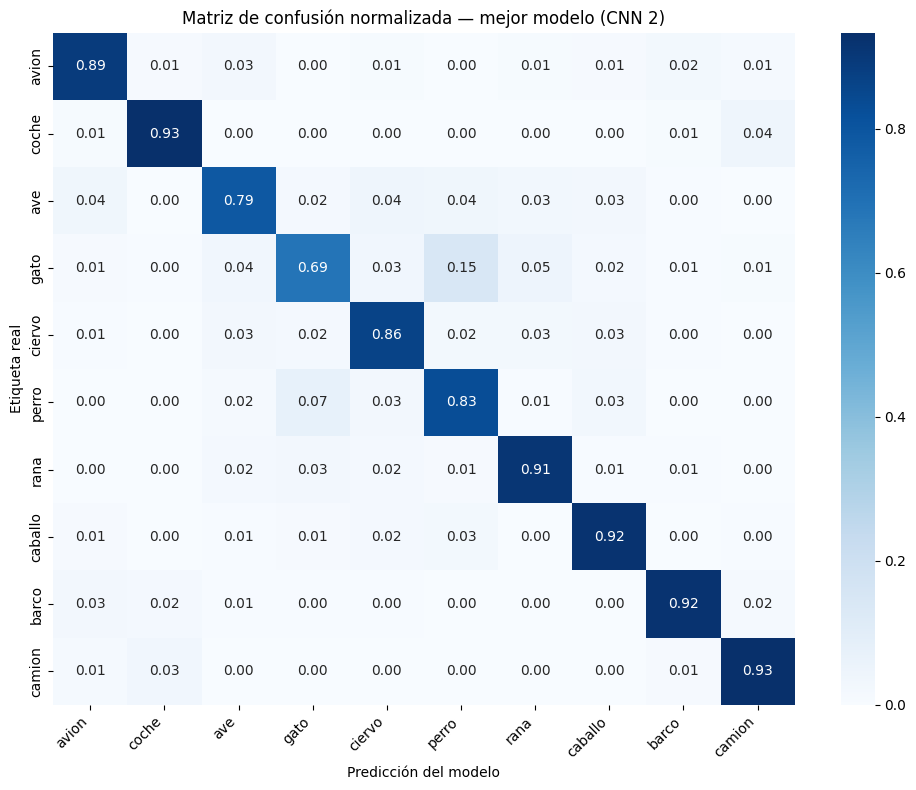

In [13]:
# ===========================
# MATRIZ DE CONFUSIÓN
# ===========================
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases, yticklabels=clases)
plt.xlabel("Predicción del modelo")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusión — mejor modelo (CNN 2)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Versión normalizada (%)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=clases, yticklabels=clases)
plt.xlabel("Predicción del modelo")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusión normalizada — mejor modelo (CNN 2)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

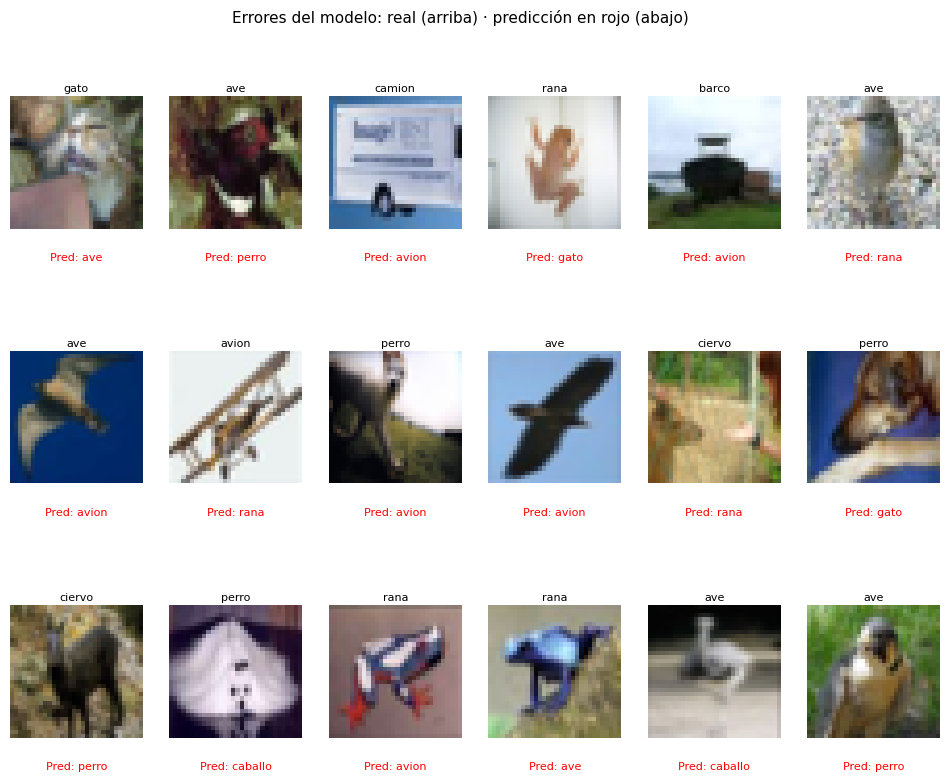


Total de errores en test: 1326 / 10000  (13.3%)


In [14]:
# ===========================
# ANÁLISIS VISUAL DE ERRORES
# ===========================
# Seleccionamos imágenes donde el modelo se equivoca y las mostramos
# con su etiqueta real (arriba) y la predicción (abajo, en rojo)

error_indices = np.where(y_pred != y_true)[0]
np.random.shuffle(error_indices)

num_cols = 6
num_rows = 3
num = min(num_cols * num_rows, len(error_indices))
seleccionados = error_indices[:num]

plt.figure(figsize=(num_cols * 2, num_rows * 2.8))
for i, idx in enumerate(seleccionados):
    ax = plt.subplot(num_rows, num_cols, i + 1)
    plt.imshow(x_test[idx])
    plt.axis('off')
    ax.set_title(MAP_ELEMENTS[y_true[idx]], fontsize=8, pad=3)
    ax.text(0.5, -0.18,
            f"Pred: {MAP_ELEMENTS[y_pred[idx]]}",
            transform=ax.transAxes,
            fontsize=8, ha='center', va='top', color='red')

plt.suptitle('Errores del modelo: real (arriba) · predicción en rojo (abajo)',
             fontsize=11)
plt.subplots_adjust(hspace=0.85)
plt.show()

print(f"\nTotal de errores en test: {len(error_indices)} / {len(y_true)}"
      f"  ({len(error_indices)/len(y_true)*100:.1f}%)")

### Conclusiones

El modelo CNN con regularización comete errores en el **13.3% de las imágenes del test** (1326 de 10000). El análisis visual de los errores revela patrones consistentes con el informe por clase:

- Las confusiones más frecuentes ocurren entre **gato/perro** y entre **ave/ciervo**, clases que comparten características visuales a baja resolución.
- En algunas imágenes el contexto (fondo, iluminación) dificulta la identificación incluso para un humano a 32×32 píxeles.

En resumen, la arquitectura CNN con regularización logra un rendimiento muy competitivo en CIFAR-10 partiendo desde cero, con una mejora de **+30 puntos porcentuales** sobre el modelo baseline fully connected, lo que demuestra el valor de las redes convolucionales para el reconocimiento de imágenes.